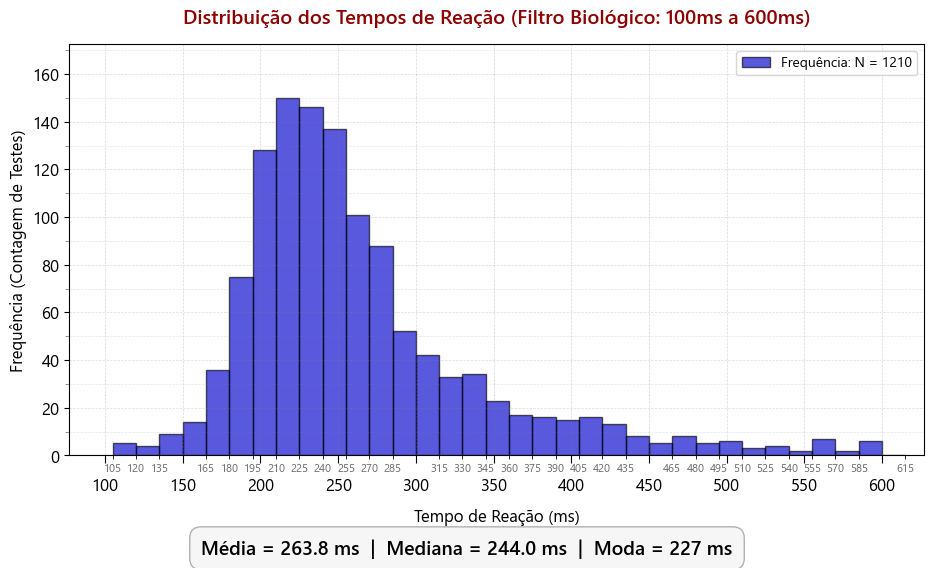

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator, AutoMinorLocator
import pandas as pd
import glob

# Configurações visuais do gráfico (Fonte Moderna para Projetor)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Calibri', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12

# ====================================================================
# 1. Carregamento Blindado e FUSÃO de todos os arquivos CSV
# ====================================================================
caminho_dos_arquivos = glob.glob('*.csv') 
lista_de_valores = []

for arquivo in caminho_dos_arquivos:
    try:
        dados_temp = pd.read_csv(arquivo, header=None)
        valores_numericos = pd.to_numeric(dados_temp.values.flatten(), errors='coerce')
        lista_de_valores.extend(valores_numericos)
    except Exception as e:
        print(f"Erro ao ler o arquivo {arquivo}: {e}")

tempos_brutos = pd.Series(lista_de_valores).dropna()

if len(tempos_brutos) == 0:
    raise ValueError("Nenhum dado numérico válido foi encontrado nos arquivos CSV!")

# ====================================================================
# 2. Filtro Fisiológico Fixo (Entre 100 ms e 600 ms - Sem IQR)
# ====================================================================
MIN_FISIOLOGICO = 100
MAX_FISIOLOGICO = 600

tempos_validos = tempos_brutos[
    (tempos_brutos >= MIN_FISIOLOGICO) & 
    (tempos_brutos <= MAX_FISIOLOGICO)
]

# ====================================================================
# 3. Cálculos Estatísticos
# ====================================================================
total_de_alunos = len(tempos_validos)
media_dos_tempos = np.mean(tempos_validos)
mediana_dos_tempos = np.median(tempos_validos)

modas = tempos_validos.mode()
moda_dos_tempos = modas.iloc[0] if not modas.empty else mediana_dos_tempos

# ====================================================================
# 4. Definição Inteligente das Barras (Regra de Freedman-Diaconis)
# ====================================================================
iqr_valido = np.subtract(*np.percentile(tempos_validos, [75, 25]))
if iqr_valido == 0: iqr_valido = 10 

largura_ideal = 2 * iqr_valido / (total_de_alunos ** (1/3))
tamanho_do_intervalo = int(np.clip(round(largura_ideal / 5) * 5, 15, 30)) 

limite_inferior_grafico = np.floor(tempos_validos.min() / tamanho_do_intervalo) * tamanho_do_intervalo
limite_superior_grafico = np.ceil(tempos_validos.max() / tamanho_do_intervalo) * tamanho_do_intervalo + tamanho_do_intervalo
lista_de_intervalos = np.arange(limite_inferior_grafico, limite_superior_grafico + tamanho_do_intervalo, tamanho_do_intervalo)

# ====================================================================
# 5. Criação da Figura e Plotagem (Apenas Histograma)
# ====================================================================
plt.figure(figsize=(9.5, 5.8))

contagens, bordas, _ = plt.hist(
    tempos_validos,
    bins=lista_de_intervalos,
    color='mediumblue',
    edgecolor='black',
    alpha=0.65,
    label=f'Frequência: N = {total_de_alunos}'
)

# ====================================================================
# 6. Textos, Eixos (Major e Minor Ticks) e Estética
# ====================================================================
plt.xlabel('Tempo de Reação (ms)', labelpad=10)
plt.ylabel('Frequência (Contagem de Testes)')
plt.title('Distribuição dos Tempos de Reação (Filtro Biológico: 100ms a 600ms)', color='darkred', fontweight='semibold', pad=15)

limite_x_esq = max(50, tempos_validos.min() - 30)
limite_x_dir = tempos_validos.max() + 30
plt.xlim(limite_x_esq, limite_x_dir)
plt.ylim(0, max(contagens) * 1.15)
plt.axhline(0, color='lightslategray', linewidth=0.8)

eixo_atual = plt.gca()

amplitude_x = limite_x_dir - limite_x_esq
passo_x = 50 if amplitude_x <= 1000 else 100

ticks_redondos = np.arange(0, limite_x_dir + passo_x, passo_x)
ticks_redondos = ticks_redondos[(ticks_redondos >= limite_x_esq) & (ticks_redondos <= limite_x_dir)]
eixo_atual.set_xticks(ticks_redondos)
eixo_atual.tick_params(axis='x', which='major', labelsize=12, pad=10, length=6)

bordas_pequenas = [b for b in bordas if b % 50 != 0]
eixo_atual.xaxis.set_minor_locator(FixedLocator(bordas_pequenas))
eixo_atual.xaxis.set_minor_formatter(FormatStrFormatter('%d'))
eixo_atual.tick_params(axis='x', which='minor', labelsize=8, labelcolor='dimgray', pad=2, length=3)

eixo_atual.yaxis.set_major_locator(MaxNLocator(integer=True))
eixo_atual.yaxis.set_minor_locator(AutoMinorLocator(2))
eixo_atual.tick_params(axis='y', which='minor', length=3, color='gray')

plt.legend(loc='upper right', fontsize=10)
plt.grid(True, which='major', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
plt.grid(True, which='minor', axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.2)

# ====================================================================
# 7. Rodapé Simplificado
# ====================================================================
texto_estatisticas = (
    f'Média = {media_dos_tempos:.1f} ms  |  '
    f'Mediana = {mediana_dos_tempos:.1f} ms  |  '
    f'Moda = {moda_dos_tempos:.0f} ms'
)

plt.figtext(
    0.5, 0.03, 
    texto_estatisticas, 
    fontsize=14,
    fontweight='semibold',
    ha='center', 
    bbox=dict(boxstyle='round,pad=0.6', facecolor='whitesmoke', edgecolor='darkgray', alpha=0.9)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)
plt.show()

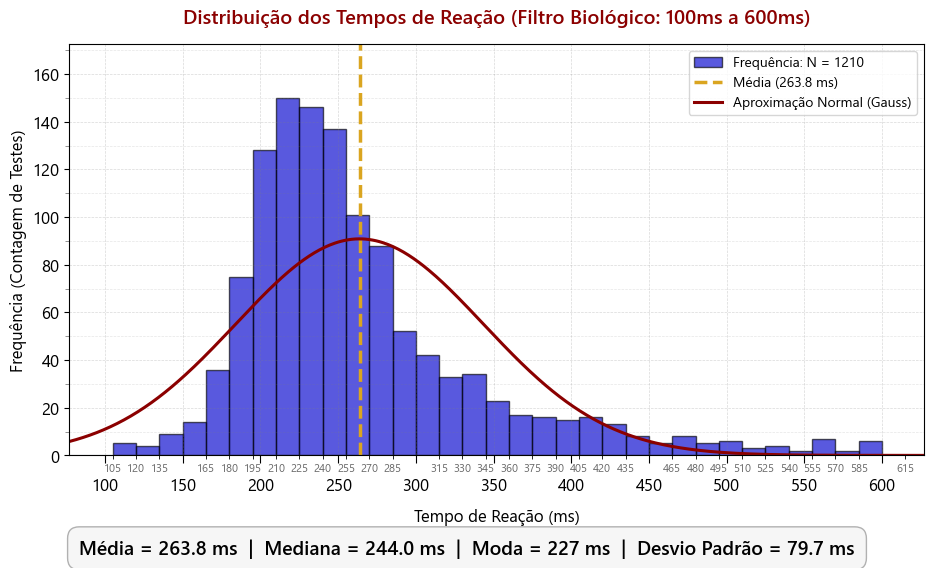

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator, AutoMinorLocator
import pandas as pd
from scipy.stats import norm
import glob

# Configurações visuais do gráfico (Fonte Moderna para Projetor)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Calibri', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12

# ====================================================================
# 1. Carregamento Blindado e FUSÃO de todos os arquivos CSV
# ====================================================================
caminho_dos_arquivos = glob.glob('*.csv') 
lista_de_valores = []

for arquivo in caminho_dos_arquivos:
    try:
        dados_temp = pd.read_csv(arquivo, header=None)
        valores_numericos = pd.to_numeric(dados_temp.values.flatten(), errors='coerce')
        lista_de_valores.extend(valores_numericos)
    except Exception as e:
        print(f"Erro ao ler o arquivo {arquivo}: {e}")

tempos_brutos = pd.Series(lista_de_valores).dropna()

if len(tempos_brutos) == 0:
    raise ValueError("Nenhum dado numérico válido foi encontrado nos arquivos CSV!")

# ====================================================================
# 2. Filtro Fisiológico Fixo (Entre 100 ms e 600 ms - Sem IQR)
# ====================================================================
MIN_FISIOLOGICO = 100
MAX_FISIOLOGICO = 600

tempos_validos = tempos_brutos[
    (tempos_brutos >= MIN_FISIOLOGICO) & 
    (tempos_brutos <= MAX_FISIOLOGICO)
]

# ====================================================================
# 3. Cálculos Estatísticos
# ====================================================================
total_de_alunos = len(tempos_validos)
media_dos_tempos = np.mean(tempos_validos)
mediana_dos_tempos = np.median(tempos_validos)
desvio_padrao = np.std(tempos_validos, ddof=1)

modas = tempos_validos.mode()
moda_dos_tempos = modas.iloc[0] if not modas.empty else mediana_dos_tempos

# ====================================================================
# 4. Definição Inteligente das Barras (Regra de Freedman-Diaconis)
# ====================================================================
iqr_valido = np.subtract(*np.percentile(tempos_validos, [75, 25]))
if iqr_valido == 0: iqr_valido = 10 

largura_ideal = 2 * iqr_valido / (total_de_alunos ** (1/3))
tamanho_do_intervalo = int(np.clip(round(largura_ideal / 5) * 5, 15, 30)) 

limite_inferior_grafico = np.floor(tempos_validos.min() / tamanho_do_intervalo) * tamanho_do_intervalo
limite_superior_grafico = np.ceil(tempos_validos.max() / tamanho_do_intervalo) * tamanho_do_intervalo + tamanho_do_intervalo
lista_de_intervalos = np.arange(limite_inferior_grafico, limite_superior_grafico + tamanho_do_intervalo, tamanho_do_intervalo)

# ====================================================================
# 5. Criação da Figura e Plotagem
# ====================================================================
plt.figure(figsize=(9.5, 5.8))

contagens, bordas, _ = plt.hist(
    tempos_validos,
    bins=lista_de_intervalos,
    color='mediumblue',
    edgecolor='black',
    alpha=0.65,
    label=f'Frequência: N = {total_de_alunos}'
)

# ====================================================================
# 6. Criação da linha da Curva Normal Padrão (Gaussiana Simétrica)
# ====================================================================
eixo_x_da_curva = np.linspace(tempos_validos.min() - 30, tempos_validos.max() + 30, 500)
probabilidade_teorica = norm.pdf(eixo_x_da_curva, media_dos_tempos, desvio_padrao)
eixo_y_da_curva = total_de_alunos * tamanho_do_intervalo * probabilidade_teorica

plt.axvline(media_dos_tempos, color='goldenrod', linestyle='dashed', linewidth=2.5, label=f'Média ({media_dos_tempos:.1f} ms)')
plt.plot(eixo_x_da_curva, eixo_y_da_curva, color='darkred', linewidth=2.2, label='Aproximação Normal (Gauss)')

# ====================================================================
# 7. Textos, Eixos (Major e Minor Ticks) e Estética
# ====================================================================
plt.xlabel('Tempo de Reação (ms)', labelpad=10)
plt.ylabel('Frequência (Contagem de Testes)')
plt.title('Distribuição dos Tempos de Reação (Filtro Biológico: 100ms a 600ms)', color='darkred', fontweight='semibold', pad=15)

limite_x_esq = max(50, tempos_validos.min() - 30)
limite_x_dir = tempos_validos.max() + 30
plt.xlim(limite_x_esq, limite_x_dir)
plt.ylim(0, max(max(contagens), max(eixo_y_da_curva)) * 1.15)
plt.axhline(0, color='lightslategray', linewidth=0.8)

eixo_atual = plt.gca()

amplitude_x = limite_x_dir - limite_x_esq
passo_x = 50 if amplitude_x <= 1000 else 100

ticks_redondos = np.arange(0, limite_x_dir + passo_x, passo_x)
ticks_redondos = ticks_redondos[(ticks_redondos >= limite_x_esq) & (ticks_redondos <= limite_x_dir)]
eixo_atual.set_xticks(ticks_redondos)
eixo_atual.tick_params(axis='x', which='major', labelsize=12, pad=10, length=6)

bordas_pequenas = [b for b in bordas if b % 50 != 0]
eixo_atual.xaxis.set_minor_locator(FixedLocator(bordas_pequenas))
eixo_atual.xaxis.set_minor_formatter(FormatStrFormatter('%d'))
eixo_atual.tick_params(axis='x', which='minor', labelsize=8, labelcolor='dimgray', pad=2, length=3)

eixo_atual.yaxis.set_major_locator(MaxNLocator(integer=True))
eixo_atual.yaxis.set_minor_locator(AutoMinorLocator(2))
eixo_atual.tick_params(axis='y', which='minor', length=3, color='gray')

plt.legend(loc='upper right', fontsize=10)
plt.grid(True, which='major', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
plt.grid(True, which='minor', axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.2)

# ====================================================================
# 8. Rodapé Simplificado e Ampliado
# ====================================================================
texto_estatisticas = (
    f'Média = {media_dos_tempos:.1f} ms  |  '
    f'Mediana = {mediana_dos_tempos:.1f} ms  |  '
    f'Moda = {moda_dos_tempos:.0f} ms  |  '
    f'Desvio Padrão = {desvio_padrao:.1f} ms'
)

plt.figtext(
    0.5, 0.03, 
    texto_estatisticas, 
    fontsize=14,
    fontweight='semibold',
    ha='center', 
    bbox=dict(boxstyle='round,pad=0.6', facecolor='whitesmoke', edgecolor='darkgray', alpha=0.9)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)
plt.show()

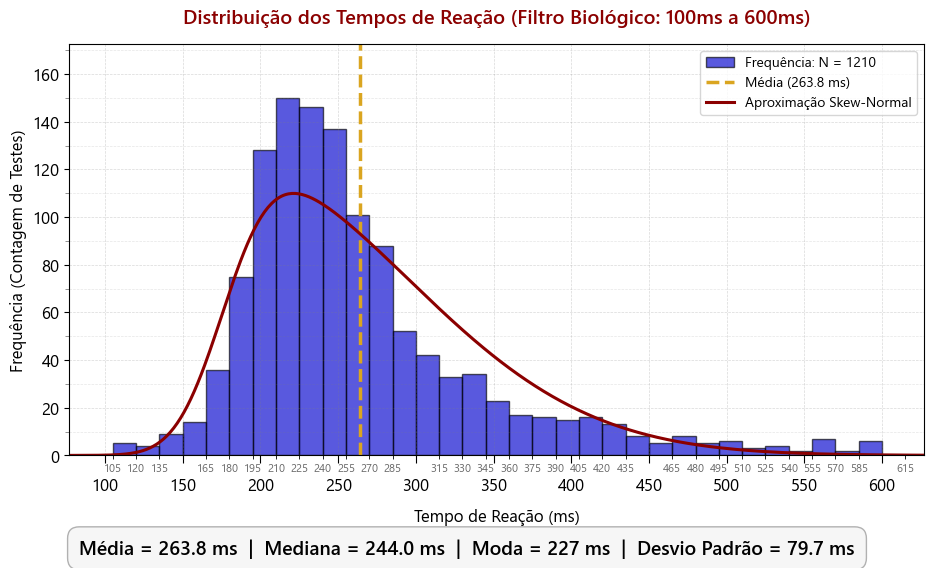

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator, AutoMinorLocator
import pandas as pd
from scipy.stats import skewnorm
import glob

# Configurações visuais do gráfico (Fonte Moderna para Projetor)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Calibri', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12

# ====================================================================
# 1. Carregamento Blindado e FUSÃO de todos os arquivos CSV
# ====================================================================
caminho_dos_arquivos = glob.glob('*.csv') 
lista_de_valores = []

for arquivo in caminho_dos_arquivos:
    try:
        dados_temp = pd.read_csv(arquivo, header=None)
        valores_numericos = pd.to_numeric(dados_temp.values.flatten(), errors='coerce')
        lista_de_valores.extend(valores_numericos)
    except Exception as e:
        print(f"Erro ao ler o arquivo {arquivo}: {e}")

tempos_brutos = pd.Series(lista_de_valores).dropna()

if len(tempos_brutos) == 0:
    raise ValueError("Nenhum dado numérico válido foi encontrado nos arquivos CSV!")

# ====================================================================
# 2. Filtro Fisiológico Fixo (Entre 100 ms e 600 ms - Sem IQR)
# ====================================================================
MIN_FISIOLOGICO = 100
MAX_FISIOLOGICO = 600

tempos_validos = tempos_brutos[
    (tempos_brutos >= MIN_FISIOLOGICO) & 
    (tempos_brutos <= MAX_FISIOLOGICO)
]

# ====================================================================
# 3. Cálculos Estatísticos
# ====================================================================
total_de_alunos = len(tempos_validos)
media_dos_tempos = np.mean(tempos_validos)
mediana_dos_tempos = np.median(tempos_validos)
desvio_padrao = np.std(tempos_validos, ddof=1)

modas = tempos_validos.mode()
moda_dos_tempos = modas.iloc[0] if not modas.empty else mediana_dos_tempos

# ====================================================================
# 4. Definição Inteligente das Barras (Regra de Freedman-Diaconis)
# ====================================================================
iqr_valido = np.subtract(*np.percentile(tempos_validos, [75, 25]))
if iqr_valido == 0: iqr_valido = 10 

largura_ideal = 2 * iqr_valido / (total_de_alunos ** (1/3))
tamanho_do_intervalo = int(np.clip(round(largura_ideal / 5) * 5, 15, 30)) 

limite_inferior_grafico = np.floor(tempos_validos.min() / tamanho_do_intervalo) * tamanho_do_intervalo
limite_superior_grafico = np.ceil(tempos_validos.max() / tamanho_do_intervalo) * tamanho_do_intervalo + tamanho_do_intervalo
lista_de_intervalos = np.arange(limite_inferior_grafico, limite_superior_grafico + tamanho_do_intervalo, tamanho_do_intervalo)

# ====================================================================
# 5. Criação da Figura e Plotagem
# ====================================================================
plt.figure(figsize=(9.5, 5.8))

contagens, bordas, _ = plt.hist(
    tempos_validos,
    bins=lista_de_intervalos,
    color='mediumblue',
    edgecolor='black',
    alpha=0.65,
    label=f'Frequência: N = {total_de_alunos}'
)

# ====================================================================
# 6. Criação da linha da Curva Normal Assimétrica (Skew-Normal)
# ====================================================================
param_a, param_loc, param_scale = skewnorm.fit(tempos_validos)

eixo_x_da_curva = np.linspace(tempos_validos.min() - 30, tempos_validos.max() + 30, 500)
probabilidade_teorica = skewnorm.pdf(eixo_x_da_curva, param_a, param_loc, param_scale)
eixo_y_da_curva = total_de_alunos * tamanho_do_intervalo * probabilidade_teorica

plt.axvline(media_dos_tempos, color='goldenrod', linestyle='dashed', linewidth=2.5, label=f'Média ({media_dos_tempos:.1f} ms)')
plt.plot(eixo_x_da_curva, eixo_y_da_curva, color='darkred', linewidth=2.2, label='Aproximação Skew-Normal')

# ====================================================================
# 7. Textos, Eixos (Major e Minor Ticks) e Estética
# ====================================================================
plt.xlabel('Tempo de Reação (ms)', labelpad=10)
plt.ylabel('Frequência (Contagem de Testes)')
plt.title('Distribuição dos Tempos de Reação (Filtro Biológico: 100ms a 600ms)', color='darkred', fontweight='semibold', pad=15)

limite_x_esq = max(50, tempos_validos.min() - 30)
limite_x_dir = tempos_validos.max() + 30
plt.xlim(limite_x_esq, limite_x_dir)
plt.ylim(0, max(max(contagens), max(eixo_y_da_curva)) * 1.15)
plt.axhline(0, color='lightslategray', linewidth=0.8)

eixo_atual = plt.gca()

amplitude_x = limite_x_dir - limite_x_esq
passo_x = 50 if amplitude_x <= 1000 else 100

ticks_redondos = np.arange(0, limite_x_dir + passo_x, passo_x)
ticks_redondos = ticks_redondos[(ticks_redondos >= limite_x_esq) & (ticks_redondos <= limite_x_dir)]
eixo_atual.set_xticks(ticks_redondos)
eixo_atual.tick_params(axis='x', which='major', labelsize=12, pad=10, length=6)

bordas_pequenas = [b for b in bordas if b % 50 != 0]
eixo_atual.xaxis.set_minor_locator(FixedLocator(bordas_pequenas))
eixo_atual.xaxis.set_minor_formatter(FormatStrFormatter('%d'))
eixo_atual.tick_params(axis='x', which='minor', labelsize=8, labelcolor='dimgray', pad=2, length=3)

eixo_atual.yaxis.set_major_locator(MaxNLocator(integer=True))
eixo_atual.yaxis.set_minor_locator(AutoMinorLocator(2))
eixo_atual.tick_params(axis='y', which='minor', length=3, color='gray')

plt.legend(loc='upper right', fontsize=10)
plt.grid(True, which='major', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
plt.grid(True, which='minor', axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.2)

# ====================================================================
# 8. Rodapé Simplificado e Ampliado
# ====================================================================
texto_estatisticas = (
    f'Média = {media_dos_tempos:.1f} ms  |  '
    f'Mediana = {mediana_dos_tempos:.1f} ms  |  '
    f'Moda = {moda_dos_tempos:.0f} ms  |  '
    f'Desvio Padrão = {desvio_padrao:.1f} ms'
)

plt.figtext(
    0.5, 0.03, 
    texto_estatisticas, 
    fontsize=14,
    fontweight='semibold',
    ha='center', 
    bbox=dict(boxstyle='round,pad=0.6', facecolor='whitesmoke', edgecolor='darkgray', alpha=0.9)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)
plt.show()

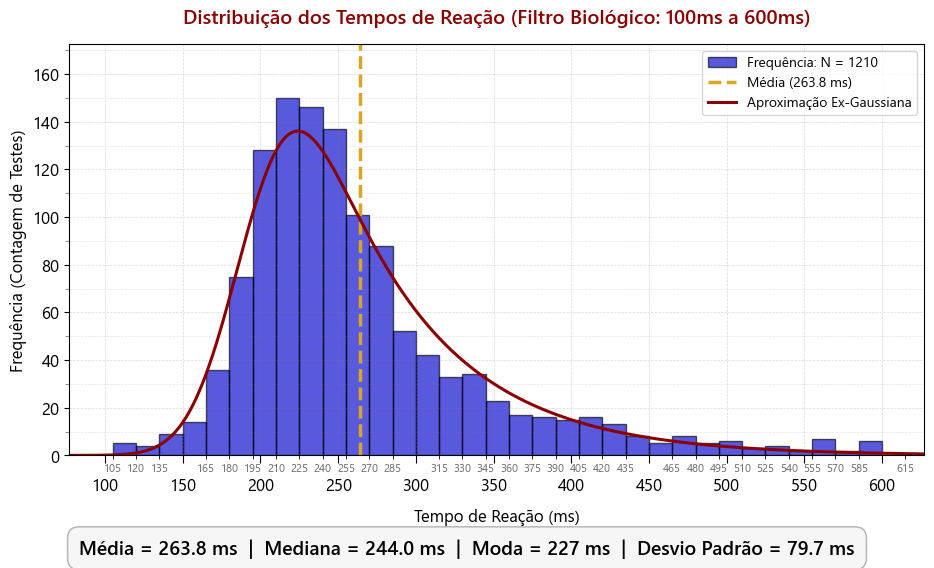

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator, AutoMinorLocator
import pandas as pd
from scipy.stats import exponnorm
import glob

# Configurações visuais do gráfico (Fonte Moderna para Projetor)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Calibri', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12

# ====================================================================
# 1. Carregamento Blindado e FUSÃO de todos os arquivos CSV
# ====================================================================
caminho_dos_arquivos = glob.glob('*.csv') 
lista_de_valores = []

for arquivo in caminho_dos_arquivos:
    try:
        dados_temp = pd.read_csv(arquivo, header=None)
        valores_numericos = pd.to_numeric(dados_temp.values.flatten(), errors='coerce')
        lista_de_valores.extend(valores_numericos)
    except Exception as e:
        print(f"Erro ao ler o arquivo {arquivo}: {e}")

tempos_brutos = pd.Series(lista_de_valores).dropna()

if len(tempos_brutos) == 0:
    raise ValueError("Nenhum dado numérico válido foi encontrado nos arquivos CSV!")

# ====================================================================
# 2. Filtro Fisiológico Fixo (Entre 100 ms e 600 ms - Sem IQR)
# ====================================================================
MIN_FISIOLOGICO = 100
MAX_FISIOLOGICO = 600

tempos_validos = tempos_brutos[
    (tempos_brutos >= MIN_FISIOLOGICO) & 
    (tempos_brutos <= MAX_FISIOLOGICO)
]

# ====================================================================
# 3. Cálculos Estatísticos
# ====================================================================
total_de_alunos = len(tempos_validos)
media_dos_tempos = np.mean(tempos_validos)
mediana_dos_tempos = np.median(tempos_validos)
desvio_padrao = np.std(tempos_validos, ddof=1)

modas = tempos_validos.mode()
moda_dos_tempos = modas.iloc[0] if not modas.empty else mediana_dos_tempos

# ====================================================================
# 4. Definição Inteligente das Barras (Regra de Freedman-Diaconis)
# ====================================================================
iqr_valido = np.subtract(*np.percentile(tempos_validos, [75, 25]))
if iqr_valido == 0: iqr_valido = 10 

largura_ideal = 2 * iqr_valido / (total_de_alunos ** (1/3))
tamanho_do_intervalo = int(np.clip(round(largura_ideal / 5) * 5, 15, 30)) 

limite_inferior_grafico = np.floor(tempos_validos.min() / tamanho_do_intervalo) * tamanho_do_intervalo
limite_superior_grafico = np.ceil(tempos_validos.max() / tamanho_do_intervalo) * tamanho_do_intervalo + tamanho_do_intervalo
lista_de_intervalos = np.arange(limite_inferior_grafico, limite_superior_grafico + tamanho_do_intervalo, tamanho_do_intervalo)

# ====================================================================
# 5. Criação da Figura e Plotagem
# ====================================================================
plt.figure(figsize=(9.5, 5.8))

contagens, bordas, _ = plt.hist(
    tempos_validos,
    bins=lista_de_intervalos,
    color='mediumblue',
    edgecolor='black',
    alpha=0.65,
    label=f'Frequência: N = {total_de_alunos}'
)

# ====================================================================
# 6. Criação da linha da Curva Ex-Gaussiana (Exponencialmente Modificada)
# ====================================================================
param_k, param_loc, param_scale = exponnorm.fit(tempos_validos)

eixo_x_da_curva = np.linspace(tempos_validos.min() - 30, tempos_validos.max() + 30, 500)
probabilidade_teorica = exponnorm.pdf(eixo_x_da_curva, param_k, param_loc, param_scale)
eixo_y_da_curva = total_de_alunos * tamanho_do_intervalo * probabilidade_teorica

plt.axvline(media_dos_tempos, color='goldenrod', linestyle='dashed', linewidth=2.5, label=f'Média ({media_dos_tempos:.1f} ms)')
plt.plot(eixo_x_da_curva, eixo_y_da_curva, color='darkred', linewidth=2.2, label='Aproximação Ex-Gaussiana')

# ====================================================================
# 7. Textos, Eixos (Major e Minor Ticks) e Estética
# ====================================================================
plt.xlabel('Tempo de Reação (ms)', labelpad=10)
plt.ylabel('Frequência (Contagem de Testes)')
plt.title('Distribuição dos Tempos de Reação (Filtro Biológico: 100ms a 600ms)', color='darkred', fontweight='semibold', pad=15)

limite_x_esq = max(50, tempos_validos.min() - 30)
limite_x_dir = tempos_validos.max() + 30
plt.xlim(limite_x_esq, limite_x_dir)
plt.ylim(0, max(max(contagens), max(eixo_y_da_curva)) * 1.15)
plt.axhline(0, color='lightslategray', linewidth=0.8)

eixo_atual = plt.gca()

amplitude_x = limite_x_dir - limite_x_esq
passo_x = 50 if amplitude_x <= 1000 else 100

ticks_redondos = np.arange(0, limite_x_dir + passo_x, passo_x)
ticks_redondos = ticks_redondos[(ticks_redondos >= limite_x_esq) & (ticks_redondos <= limite_x_dir)]
eixo_atual.set_xticks(ticks_redondos)
eixo_atual.tick_params(axis='x', which='major', labelsize=12, pad=10, length=6)

bordas_pequenas = [b for b in bordas if b % 50 != 0]
eixo_atual.xaxis.set_minor_locator(FixedLocator(bordas_pequenas))
eixo_atual.xaxis.set_minor_formatter(FormatStrFormatter('%d'))
eixo_atual.tick_params(axis='x', which='minor', labelsize=8, labelcolor='dimgray', pad=2, length=3)

eixo_atual.yaxis.set_major_locator(MaxNLocator(integer=True))
eixo_atual.yaxis.set_minor_locator(AutoMinorLocator(2))
eixo_atual.tick_params(axis='y', which='minor', length=3, color='gray')

plt.legend(loc='upper right', fontsize=10)
plt.grid(True, which='major', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
plt.grid(True, which='minor', axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.2)

# ====================================================================
# 8. Rodapé Simplificado e Ampliado
# ====================================================================
texto_estatisticas = (
    f'Média = {media_dos_tempos:.1f} ms  |  '
    f'Mediana = {mediana_dos_tempos:.1f} ms  |  '
    f'Moda = {moda_dos_tempos:.0f} ms  |  '
    f'Desvio Padrão = {desvio_padrao:.1f} ms'
)

plt.figtext(
    0.5, 0.03, 
    texto_estatisticas, 
    fontsize=14,
    fontweight='semibold',
    ha='center', 
    bbox=dict(boxstyle='round,pad=0.6', facecolor='whitesmoke', edgecolor='darkgray', alpha=0.9)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)
plt.show()

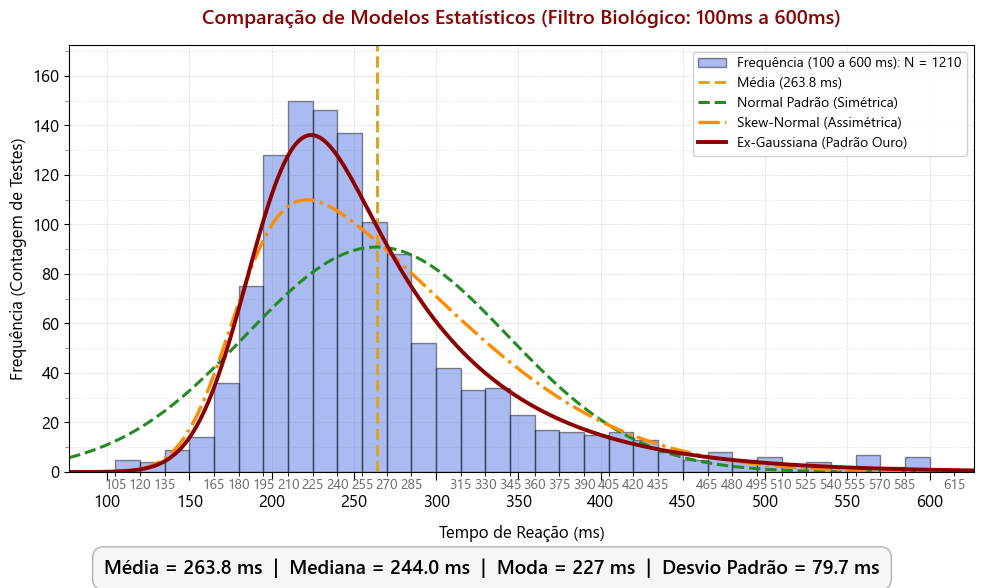

In [1]:
import glob
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, FixedLocator, FormatStrFormatter, MaxNLocator
import numpy as np
import pandas as pd
from scipy.stats import exponnorm, norm, skewnorm

# Configurações visuais do gráfico (Fonte Moderna para Projetor)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [
    'Segoe UI',
    'Calibri',
    'Arial',
    'DejaVu Sans',
]
plt.rcParams['font.size'] = 12

# ====================================================================
# 1. Carregamento Blindado e FUSÃO de todos os arquivos CSV
# ====================================================================
caminho_dos_arquivos = glob.glob('*.csv')
lista_de_valores = []

for arquivo in caminho_dos_arquivos:
  try:
    dados_temp = pd.read_csv(arquivo, header=None)
    valores_numericos = pd.to_numeric(
        dados_temp.values.flatten(), errors='coerce'
    )
    lista_de_valores.extend(valores_numericos)
  except Exception as e:
    print(f'Erro ao ler o arquivo {arquivo}: {e}')

tempos_brutos = pd.Series(lista_de_valores).dropna()

if len(tempos_brutos) == 0:
  raise ValueError('Nenhum dado numérico válido foi encontrado nos arquivos CSV!')

# ====================================================================
# 2. Filtro Fisiológico Fixo (Entre 100 ms e 600 ms - Sem IQR)
# ====================================================================
MIN_FISIOLOGICO = 100
MAX_FISIOLOGICO = 600

tempos_validos = tempos_brutos[
    (tempos_brutos >= MIN_FISIOLOGICO) & (tempos_brutos <= MAX_FISIOLOGICO)
]

# ====================================================================
# 3. Cálculos Estatísticos
# ====================================================================
total_de_alunos = len(tempos_validos)
media_dos_tempos = np.mean(tempos_validos)
mediana_dos_tempos = np.median(tempos_validos)
desvio_padrao = np.std(tempos_validos, ddof=1)

modas = tempos_validos.mode()
moda_dos_tempos = modas.iloc[0] if not modas.empty else mediana_dos_tempos

# ====================================================================
# 4. Definição Inteligente das Barras (Regra de Freedman-Diaconis)
# ====================================================================
iqr_valido = np.subtract(*np.percentile(tempos_validos, [75, 25]))
if iqr_valido == 0:
  iqr_valido = 10

largura_ideal = 2 * iqr_valido / (total_de_alunos ** (1 / 3))
tamanho_do_intervalo = int(np.clip(round(largura_ideal / 5) * 5, 15, 30))

limite_inferior_grafico = (
    np.floor(tempos_validos.min() / tamanho_do_intervalo) * tamanho_do_intervalo
)
limite_superior_grafico = (
    np.ceil(tempos_validos.max() / tamanho_do_intervalo) * tamanho_do_intervalo
    + tamanho_do_intervalo
)
lista_de_intervalos = np.arange(
    limite_inferior_grafico,
    limite_superior_grafico + tamanho_do_intervalo,
    tamanho_do_intervalo,
)

# ====================================================================
# 5. Criação da Figura e Plotagem do Histograma
# ====================================================================
plt.figure(figsize=(10, 6))

contagens, bordas, _ = plt.hist(
    tempos_validos,
    bins=lista_de_intervalos,
    color='royalblue',
    edgecolor='black',
    alpha=0.45,
    label=f'Frequência (100 a 600 ms): N = {total_de_alunos}',
)

# ====================================================================
# 6. Cálculo e Plotagem das 3 Curvas (Com Cores Diferentes)
# ====================================================================
eixo_x_da_curva = np.linspace(
    tempos_validos.min() - 30, tempos_validos.max() + 30, 500
)
fator_escala = total_de_alunos * tamanho_do_intervalo

# 6.1 Curva Normal Padrão (Gaussiana Simétrica) - Verde Tracejada
pdf_normal = norm.pdf(eixo_x_da_curva, media_dos_tempos, desvio_padrao)
y_normal = fator_escala * pdf_normal

# 6.2 Curva Normal Assimétrica (Skew-Normal) - Laranja Ponto-Traço
param_a, loc_skew, scale_skew = skewnorm.fit(tempos_validos)
pdf_skew = skewnorm.pdf(eixo_x_da_curva, param_a, loc_skew, scale_skew)
y_skew = fator_escala * pdf_skew

# 6.3 Curva Ex-Gaussiana (Modelo Definitivo) - Vermelho Escuro Contínua
param_k, loc_ex, scale_ex = exponnorm.fit(tempos_validos)
pdf_exgauss = exponnorm.pdf(eixo_x_da_curva, param_k, loc_ex, scale_ex)
y_exgauss = fator_escala * pdf_exgauss

# Linha da Média
plt.axvline(
    media_dos_tempos,
    color='goldenrod',
    linestyle='dashed',
    linewidth=2.2,
    label=f'Média ({media_dos_tempos:.1f} ms)',
)

# Plotagem das Curvas
plt.plot(
    eixo_x_da_curva,
    y_normal,
    color='forestgreen',
    linestyle='--',
    linewidth=2.2,
    label='Normal Padrão (Simétrica)',
)
plt.plot(
    eixo_x_da_curva,
    y_skew,
    color='darkorange',
    linestyle='-.',
    linewidth=2.4,
    label='Skew-Normal (Assimétrica)',
)
plt.plot(
    eixo_x_da_curva,
    y_exgauss,
    color='darkred',
    linestyle='-',
    linewidth=2.8,
    label='Ex-Gaussiana (Padrão Ouro)',
)

# ====================================================================
# 7. Textos, Eixos (Major e Minor Ticks) e Estética
# ====================================================================
plt.xlabel('Tempo de Reação (ms)', labelpad=10)
plt.ylabel('Frequência (Contagem de Testes)')
plt.title(
    'Comparação de Modelos Estatísticos (Filtro Biológico: 100ms a 600ms)',
    color='darkred',
    fontweight='semibold',
    pad=15,
)

limite_x_esq = max(50, tempos_validos.min() - 30)
limite_x_dir = tempos_validos.max() + 30
plt.xlim(limite_x_esq, limite_x_dir)

maior_y = max(max(contagens), max(y_normal), max(y_skew), max(y_exgauss))
plt.ylim(0, maior_y * 1.15)
plt.axhline(0, color='lightslategray', linewidth=0.8)

eixo_atual = plt.gca()

amplitude_x = limite_x_dir - limite_x_esq
passo_x = 50 if amplitude_x <= 1000 else 100

ticks_redondos = np.arange(0, limite_x_dir + passo_x, passo_x)
ticks_redondos = ticks_redondos[
    (ticks_redondos >= limite_x_esq) & (ticks_redondos <= limite_x_dir)
]
eixo_atual.set_xticks(ticks_redondos)
eixo_atual.tick_params(axis='x', which='major', labelsize=12, pad=10, length=6)

bordas_pequenas = [b for b in bordas if b % 50 != 0]
eixo_atual.xaxis.set_minor_locator(FixedLocator(bordas_pequenas))
eixo_atual.xaxis.set_minor_formatter(FormatStrFormatter('%d'))
eixo_atual.tick_params(
    axis='x', which='minor', labelsize=10, labelcolor='dimgray', pad=2, length=3
)

eixo_atual.yaxis.set_major_locator(MaxNLocator(integer=True))
eixo_atual.yaxis.set_minor_locator(AutoMinorLocator(2))
eixo_atual.tick_params(axis='y', which='minor', length=3, color='gray')

plt.legend(loc='upper right', fontsize=10, framealpha=0.9)
plt.grid(True, which='major', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
plt.grid(
    True,
    which='minor',
    axis='y',
    color='gray',
    linestyle='--',
    linewidth=0.5,
    alpha=0.2,
)

# ====================================================================
# 8. Rodapé Simplificado e Ampliado
# ====================================================================
texto_estatisticas = (
    f'Média = {media_dos_tempos:.1f} ms  |  '
    f'Mediana = {mediana_dos_tempos:.1f} ms  |  '
    f'Moda = {moda_dos_tempos:.0f} ms  |  '
    f'Desvio Padrão = {desvio_padrao:.1f} ms'
)

plt.figtext(
    0.5,
    0.03,
    texto_estatisticas,
    fontsize=14,
    fontweight='semibold',
    ha='center',
    bbox=dict(
        boxstyle='round,pad=0.6',
        facecolor='whitesmoke',
        edgecolor='darkgray',
        alpha=0.9,
    ),
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)
plt.show()